# A/B-тест рекомендательного алгоритма: дизайн и решение о внедрении

**Учебный продуктовый эксперимент.** Цель — проверить, повысила ли новая модель рекомендаций долю первых сессий, в которых пользователь просмотрел не менее четырёх страниц.

**Стек:** Python, pandas, SciPy, statsmodels, Matplotlib, seaborn. **Данные:** CSV-файлы в папке `data/`.

## Данные и метрика

История сессий за август–сентябрь 2025 года, мониторинг первого дня и результаты эксперимента за октябрь–ноябрь 2025 года. Единица анализа — **уникальный пользователь по первой сессии** (`session_number == 1`). Успех: `page_counter >= 4`. Для финального сравнения используется период **14–20 октября 2025 года**.

### 1. Работа с историческими данными (EDA)

#### 1.1. Загрузка исторических данных

Загружаем историю пользовательских сессий и знакомимся с набором данных.

In [1]:
import pandas as pd
sessions_history = pd.read_csv('data/sessions_project_history.csv')
sessions_history.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


#### 1.2. Знакомство с данными

Проверяем уникальность сессий и пользователей, рассматриваем структуру данных.

In [2]:
duplicate_sessions = sessions_history['session_id'].duplicated().sum()
first_session_rows = sessions_history[sessions_history['session_number'] == 1]
duplicate_first_users = first_session_rows['user_id'].duplicated().sum()
print(f'Дубликаты session_id: {duplicate_sessions}')
print(f'Пользователи с несколькими первыми сессиями: {duplicate_first_users}')

Дубликаты session_id: 0
Пользователи с несколькими первыми сессиями: 0


In [3]:
session_counts = sessions_history.groupby('user_id')['session_id'].nunique()
display(session_counts.describe())

count    134039.000000
mean          3.252218
std           1.292420
min           1.000000
25%           2.000000
50%           3.000000
75%           4.000000
max          10.000000
Name: session_id, dtype: float64

Выберем пользователя с `user_id` 10E0DEFC1ABDBBE0

In [4]:
display(sessions_history[sessions_history['session_number'] == 1].head())

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


#### 1.3. Анализ числа регистраций

Сравниваем динамику первых сессий и статуса регистрации, а не число новых регистраций в день.

In [5]:
daily_stats = (
    sessions_history[sessions_history['session_number'] == 1]
    .groupby('session_date', as_index=False)
    .agg(cnt_user=('user_id', 'nunique'),
         registered_at_first_session=('registration_flag', 'sum'))
)
display(daily_stats.head())

,session_date,cnt_user,registered_at_first_session
0,2025-08-11,3919,169
1,2025-08-12,4106,190
2,2025-08-13,5087,195
3,2025-08-14,5456,209
4,2025-08-15,7801,339


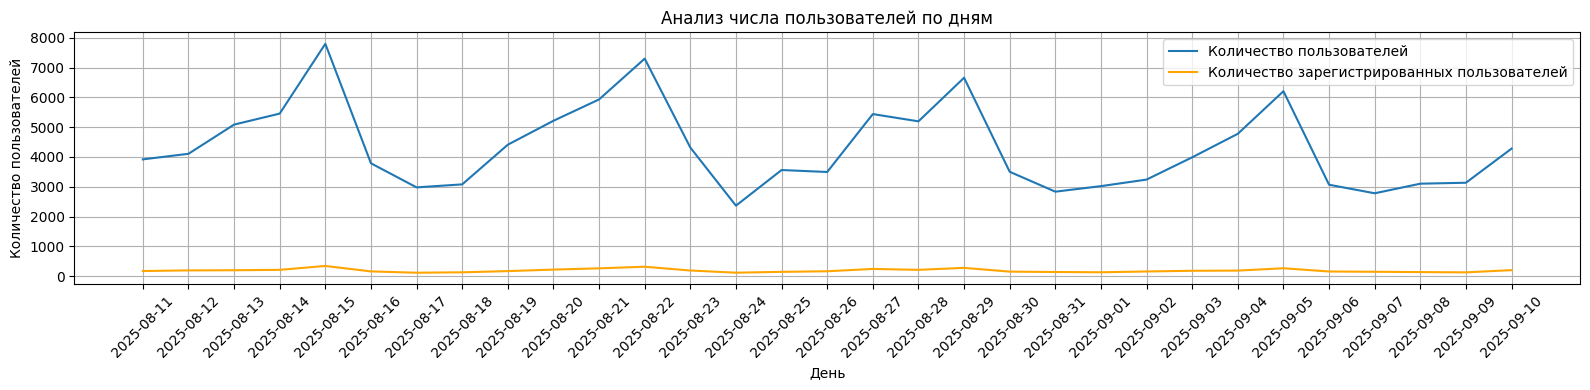

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(16, 4))

sns.lineplot(
    data=daily_stats,
    x='session_date',
    y='cnt_user',
    ax=ax,
    label='Количество пользователей'
)

sns.lineplot(
    data=daily_stats,
    x='session_date',
    y='registered_at_first_session',
    ax=ax,
    label='Количество зарегистрированных пользователей',
    color='orange'
)

ax.set_title('Анализ числа пользователей по дням')
ax.set_xlabel('День')
plt.xticks(rotation=45)
ax.set_ylabel('Количество пользователей')
plt.grid()
plt.tight_layout()
plt.show()

В начале периода наблюдается рост общего числа пользователей, после чего показатель достигает пика в конце августа — начале сентября. Начиная примерно с 10 сентября, трафик заметно снижается, и к концу периода число пользователей становится минимальным.

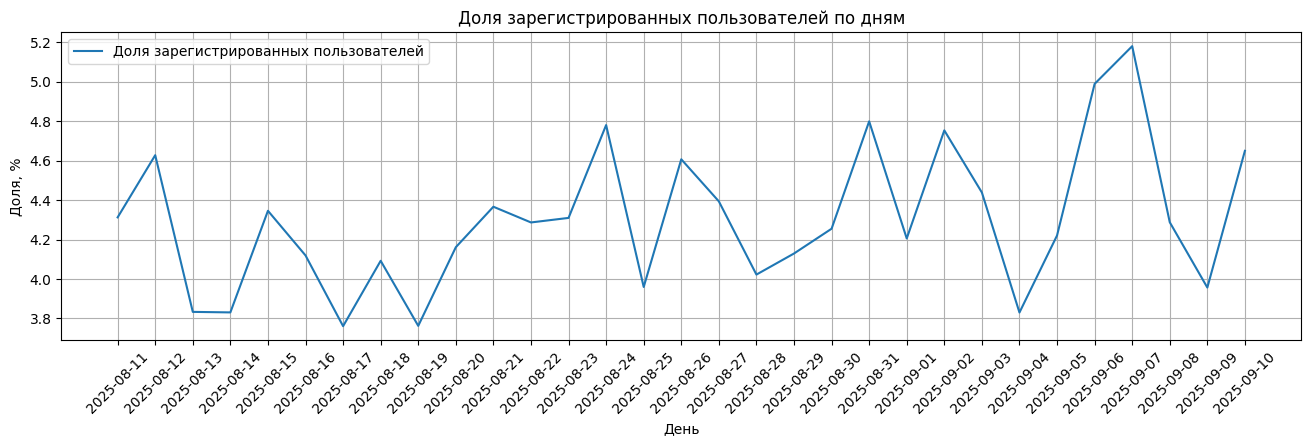

In [7]:
daily_stats['ratio'] = (daily_stats['registered_at_first_session'] / daily_stats['cnt_user']) * 100

plt.figure(figsize=(16, 4))

sns.lineplot(
    data=daily_stats,
    x='session_date',
    y='ratio',
    label='Доля зарегистрированных пользователей'
)

plt.title('Доля зарегистрированных пользователей по дням')
plt.xlabel('День')
plt.ylabel('Доля, %')
plt.xticks(rotation=45)
plt.grid()
plt.show()

Доля зарегистрированных пользователей в целом растёт на протяжении периода наблюдения. Если в начале она была около 4–6%, то к концу периода достигает примерно 10–12%. Это говорит о том, что несмотря на снижение общего трафика, относительная доля зарегистрированных пользователей со временем увеличивалась.

#### 1.4. Анализ числа просмотренных страниц

Смотрим распределение глубины просмотра во время первой сессии.

In [8]:
first_sessions = sessions_history[sessions_history['session_number'] == 1].copy()
page_distribution = first_sessions.groupby('page_counter', as_index=False)['session_id'].count()
display(page_distribution)

,page_counter,session_id
0,1,8978
1,2,32494
2,3,50939
3,4,32739
4,5,8075
5,6,777
6,7,37


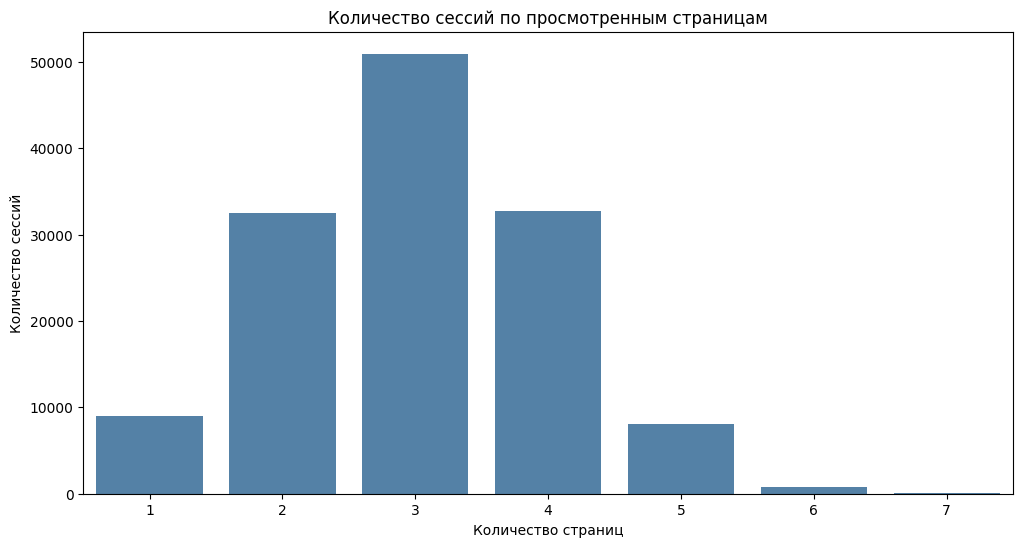

In [9]:
plt.figure(figsize=(12,6))

sns.barplot(
    data = page_distribution,
    x = 'page_counter',
    y = 'session_id',
    color='steelblue'
)
plt.title('Количество сессий по просмотренным страницам')
plt.xlabel('Количество страниц')
plt.ylabel('Количество сессий')
plt.show()

Наиболее часто пользователи просматривают 3 страницы за сессию — это самый распространённый сценарий.

#### 1.5. Доля пользователей, просмотревших более четырёх страниц

Рассчитываем историческую долю успешных первых сессий.

In [10]:
first_sessions['good_session'] = (first_sessions['page_counter'] >= 4).astype(int)
historical_success_rate = first_sessions['good_session'].mean()
avg_good_ses = first_sessions.groupby('session_date', as_index=False)['good_session'].mean()
print(f'Историческая доля успешных первых сессий: {historical_success_rate:.2%}')

Историческая доля успешных первых сессий: 31.06%


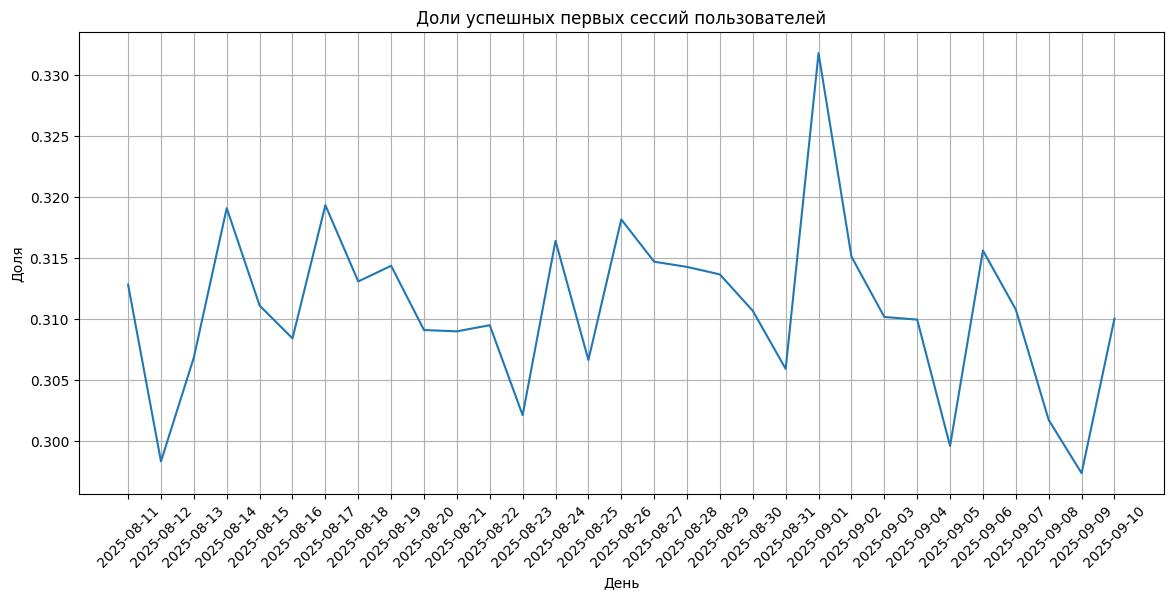

In [11]:
plt.figure(figsize=(14,6))

sns.lineplot(
    data = avg_good_ses,
    x = 'session_date',
    y = 'good_session'
)
plt.title('Доли успешных первых сессий пользователей')
plt.xlabel('День')
plt.ylabel('Доля')
plt.xticks(rotation=45)
plt.grid()
plt.show()

Доля успешных первых сессий пользователей в течение всего периода оставалась достаточно стабильной. Явного устойчивого роста или снижения не наблюдается, хотя в отдельные дни есть небольшие всплески и просадки.

### 2. Подготовка к тесту
При планировании теста необходимо проделать несколько важных шагов:

- Определиться с целевой метрикой.

- Рассчитать необходимый размер выборки.

- Исходя из текущих значений трафика рассчитать необходимую длительность проведения теста.

#### 2.1. Расчёт размера выборки

При MDE = +5% относительно исторической доли, alpha = 0.05 и мощности 80% вычисляем размер группы для одностороннего z-теста долей.

In [12]:
from math import ceil
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

alpha = 0.05
power = 0.80
relative_mde = 0.05  # Ожидаемый относительный рост на 5%
p1 = historical_success_rate
p2 = p1 * (1 + relative_mde)
absolute_mde = p2 - p1
effect_size = proportion_effectsize(p2, p1)
sample_size = ceil(NormalIndPower().solve_power(
    effect_size=effect_size, power=power, alpha=alpha,
    ratio=1, alternative='larger'
))
print(f'Базовая метрика: {p1:.2%}; ожидаемая: {p2:.2%}')
print(f'Абсолютный MDE: {absolute_mde:.4f} ({absolute_mde * 100:.2f} п.п.)')
print(f'Размер каждой группы: {sample_size} пользователей')

Базовая метрика: 31.06%; ожидаемая: 32.61%
Абсолютный MDE: 0.0155 (1.55 п.п.)
Размер каждой группы: 11127 пользователей


#### 2.2. Расчёт длительности A/B-теста

Оцениваем длительность набора выборки по историческому числу новых первых сессий в день.

In [13]:
avg_first_sessions_daily = daily_stats['cnt_user'].mean()
test_duration = ceil(2 * sample_size / avg_first_sessions_daily)
print(f'Среднее число первых сессий в день: {avg_first_sessions_daily:.1f}')
print(f'Плановая длительность теста: {test_duration} дней')

Среднее число первых сессий в день: 4323.8
Плановая длительность теста: 6 дней


### 3. Мониторинг А/В-теста

#### 3.1. Проверка распределения пользователей

Сравниваем размеры тестовой и контрольной групп в день запуска.

In [14]:
sessions_test_part = pd.read_csv('data/sessions_project_test_part.csv')
sessions_test_part.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,3404844B53442747,B4901323BD537E45,2025-10-14,2025-10-14 19:28:49,2025-10-14,1,0,3,CIS,Android,B
1,3A2BF4D364E62D89,216FC619308F8788,2025-10-14,2025-10-14 21:11:04,2025-10-14,1,0,3,MENA,iPhone,A
2,79CDAE11E32B1597,EDFCE4AC1A504074,2025-10-14,2025-10-14 21:44:03,2025-10-14,1,0,3,CIS,iPhone,A
3,D6AF8D78297A931F,CF0AC0EEDE92C690,2025-10-14,2025-10-14 19:07:55,2025-10-14,1,0,4,CIS,PC,A
4,37E0CE723AE568E0,2E6ED45E8C86C4E9,2025-10-14,2025-10-14 15:39:44,2025-10-14,1,0,3,CIS,Mac,B


In [15]:
cnt_by_grp = sessions_test_part.groupby('test_group')['user_id'].nunique().reset_index()
cnt_by_grp

,test_group,user_id
0,A,1477
1,B,1466


In [16]:
group_sizes = cnt_by_grp.set_index('test_group')['user_id']
percent_diff = abs(group_sizes['A'] - group_sizes['B']) / group_sizes.mean() * 100
print(f'Разница в численности групп: {percent_diff:.2f}%')

Разница в численности групп: 0.75%


In [17]:
total_grp = cnt_by_grp['user_id'].sum()
cnt_by_grp['ratio'] = round(cnt_by_grp['user_id'] / total_grp * 100,2)


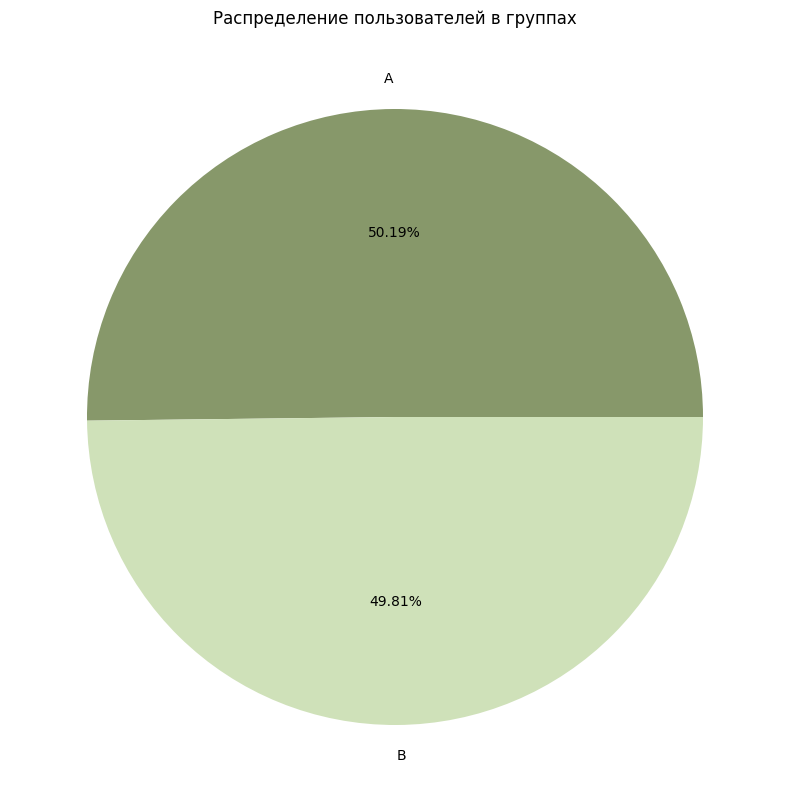

In [18]:
plt.figure(figsize=(10,10))

plt.pie(
    x = cnt_by_grp['ratio'],
    labels = cnt_by_grp['test_group'],
    autopct='%1.2f%%',
    colors = ['#87986a','#cfe1b9']
)
plt.title('Распределение пользователей в группах')
plt.show()

В группах пользователи разделены правильным образом.

#### 3.2. Пересечения пользователей

Проверяем, что один и тот же `user_id` не попал одновременно в контрольную и тестовую группы.

In [19]:
A_users = set(sessions_test_part[sessions_test_part['test_group'] == 'A']['user_id'])
B_users = set(sessions_test_part[sessions_test_part['test_group'] == 'B']['user_id'])

intersection = list(A_users & B_users)
intersection

[]

Пользователи которые пересикаются в обеих группах не присутсвуют.

#### 3.3. Равномерность разделения пользователей по устройствам

Сравниваем устройство пользователей обеих групп.

In [20]:
A_dev_grp = (
    sessions_test_part[sessions_test_part['test_group'] == 'A']
    .groupby('device')['user_id']
    .nunique()
    .reset_index()
)

A_dev_grp['share'] = A_dev_grp['user_id'] / A_dev_grp['user_id'].sum()
A_dev_grp['test_group'] = 'A'
A_dev_grp = A_dev_grp.sort_values('share', ascending=False)


B_dev_grp = (
    sessions_test_part[sessions_test_part['test_group'] == 'B']
    .groupby('device')['user_id']
    .nunique()
    .reset_index()
)

B_dev_grp['share'] = B_dev_grp['user_id'] / B_dev_grp['user_id'].sum()
B_dev_grp['test_group'] = 'B'
B_dev_grp = B_dev_grp.sort_values('share', ascending=False)


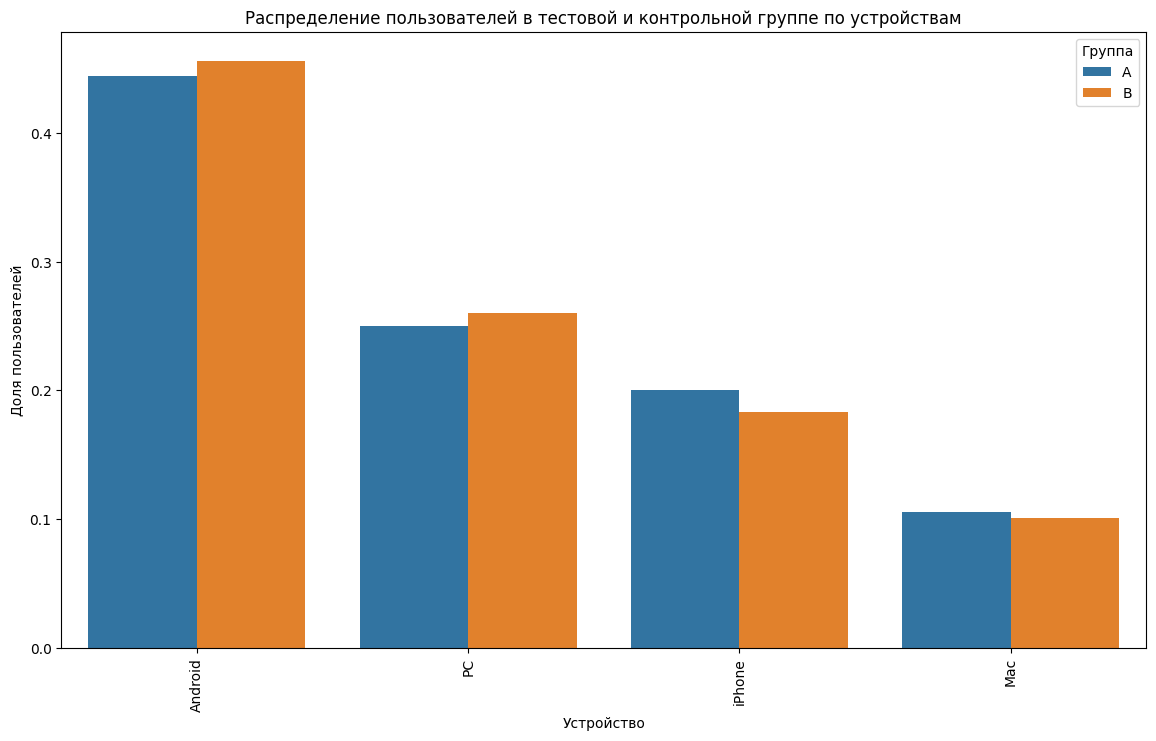

In [21]:
dev_plot = pd.concat([A_dev_grp, B_dev_grp], ignore_index=True)

plt.figure(figsize=(14, 8))

sns.barplot(
    data=dev_plot,
    x='device',
    y='share',
    hue='test_group'
)

plt.title('Распределение пользователей в тестовой и контрольной группе по устройствам')
plt.xlabel('Устройство')
plt.ylabel('Доля пользователей')
plt.legend(title='Группа')
plt.xticks(rotation=90)
plt.show()

Распределение пользователей по типам устройств в группах A и B является очень близким. В обеих группах наибольшую долю составляют пользователи Android, затем идут PC, iPhone и Mac. Различия между долями по каждому устройству незначительны, поэтому можно сделать вывод, что тестовая и контрольная группы распределены по устройствам достаточно равномерно.

#### 3.4. Равномерность распределения пользователей по регионам

Сравниваем распределения регионов обеих групп.

In [22]:
A_reg_grp = (
    sessions_test_part[sessions_test_part['test_group'] == 'A']
    .groupby('region')['user_id']
    .nunique()
    .reset_index(name='users_cnt')
)
A_reg_grp['share'] = A_reg_grp['users_cnt'] / A_reg_grp['users_cnt'].sum()
A_reg_grp['group'] = 'A'

B_reg_grp = (
    sessions_test_part[sessions_test_part['test_group'] == 'B']
    .groupby('region')['user_id']
    .nunique()
    .reset_index(name='users_cnt')
)
B_reg_grp['share'] = B_reg_grp['users_cnt'] / B_reg_grp['users_cnt'].sum()
B_reg_grp['group'] = 'B'

reg_grp = pd.concat([A_reg_grp, B_reg_grp], ignore_index=True)

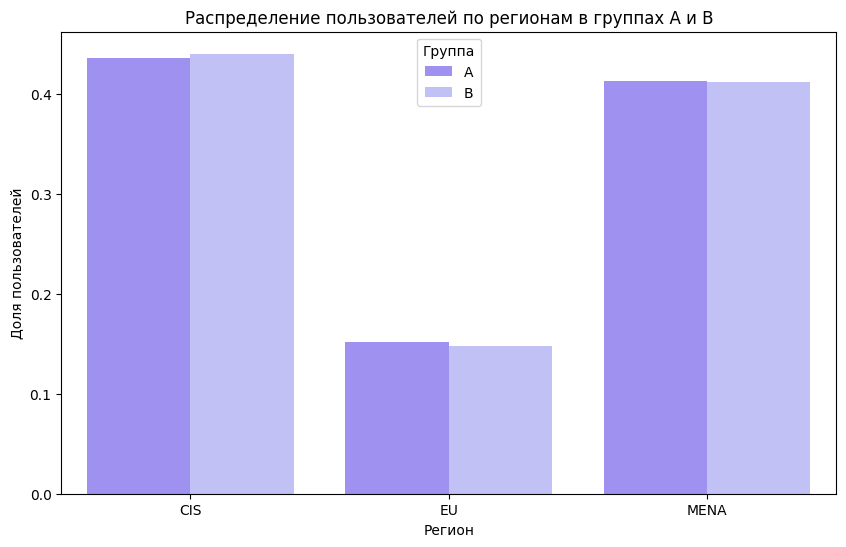

In [23]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=reg_grp,
    x='region',
    y='share',
    hue='group',
    palette=['#9381ff', '#b8b8ff']
)

plt.title('Распределение пользователей по регионам в группах A и B')
plt.xlabel('Регион')
plt.ylabel('Доля пользователей')
plt.legend(title='Группа')
plt.show()

Распределение пользователей по регионам в группах A и B практически совпадает. Наибольшая доля пользователей в обеих группах приходится на CIS и MENA, тогда как доля пользователей из EU заметно ниже.

#### 3.5. Вывод после проверки A/B-теста

Проверяем баланс групп, независимость назначений и сопоставимость категорий.

По результатам проведённой проверки A/B-теста можно сделать вывод, что тест в целом организован корректно. Существенного различия в количестве пользователей между группами A и B не обнаружено: размеры групп являются сопоставимыми, выраженного дисбаланса не наблюдается. Также выборки можно считать независимыми, поскольку пересечений пользователей между группами A и B выявлено не было.

### 4. Проверка результатов A/B-теста

A/B-тест завершён, и у вас есть результаты за все дни проведения эксперимента. Необходимо убедиться в корректности теста и верно интерпретировать результаты.

#### 4.1. Получение результатов теста и подсчёт основной метрики

Загружаем полные результаты и размечаем успешные сессии.

In [24]:
sessions_test = pd.read_csv('data/sessions_project_test.csv')
sessions_test.head(3)

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A


In [25]:
sessions_test['good_session'] = (sessions_test['page_counter'] >= 4).astype(int)

#### 4.2 Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик

Целевая метрика — доля успешных первых сессий; целевой эффект — рост в B. Барьерные метрики нужны перед полноценным внедрением.

**Целевая метрика:** доля успешных первых сессий (`good_session=1`). **Прокси-метрика:** глубина просмотра `page_counter`. **Барьерные метрики:** задержки, технические ошибки и ухудшение рекламной/подписочной конверсии (не представлены в данных).

**H0:** p(B) ≤ p(A). **H1:** p(B) > p(A).

#### 4.3. Сравнение доли успешных сессий

Рассчитываем разницу долей в семидневном окне на уровне уникального пользователя.

In [26]:
test_first_sessions = sessions_test[
    (sessions_test['session_number'] == 1) &
    (pd.to_datetime(sessions_test['session_date']).between('2025-10-14', '2025-10-20'))
].copy()
duplicate_users = test_first_sessions['user_id'].duplicated().sum()
print(f'Повторных первых сессий одного пользователя: {duplicate_users}')
if duplicate_users:
    raise ValueError('Нарушена уникальность первых сессий по user_id')
first_ses = test_first_sessions
A_avg_ses = first_ses.loc[first_ses['test_group'] == 'A', 'good_session'].mean()
B_avg_ses = first_ses.loc[first_ses['test_group'] == 'B', 'good_session'].mean()
diff = B_avg_ses - A_avg_ses
print(f'Группа A: {A_avg_ses:.4%}, группа B: {B_avg_ses:.4%}')
print(f'Разница B − A: {diff * 100:.3f} п.п.; относительное изменение: {diff / A_avg_ses:.2%}')
print('Количество пользователей:', first_ses.groupby('test_group')['user_id'].nunique().to_dict())
print(f'Размер каждой группы достаточен: {all(first_ses.groupby("test_group")["user_id"].nunique() >= sample_size)}; требуемый размер {sample_size}')

Повторных первых сессий одного пользователя: 0
Группа A: 31.4999%, группа B: 31.2345%
Разница B − A: -0.265 п.п.; относительное изменение: -0.84%
Количество пользователей: {'A': 15108, 'B': 15342}
Размер каждой группы достаточен: True; требуемый размер 11127


**Контроль качества A/B-теста.** Дополнительно проверяем SRM (ожидаемое распределение пользователей 50/50) и различия состава групп по устройствам и регионам. Небольшой p-value в этих проверках требовал бы дальнейшего расследования, даже если основная метрика выглядела значимой.

In [27]:
# Проверка Sample Ratio Mismatch и распределения по основным категориям.
from scipy.stats import chisquare, chi2_contingency

actual_group_counts = first_ses['test_group'].value_counts().reindex(['A', 'B'], fill_value=0)
srm_stat, srm_p = chisquare(actual_group_counts, f_exp=[len(first_ses) / 2] * 2)
print(f'SRM, p-value: {srm_p:.4f}; размеры групп: {actual_group_counts.to_dict()}')
for column in ['device', 'region']:
    chi2, p_value_balance, _, _ = chi2_contingency(pd.crosstab(first_ses['test_group'], first_ses[column]))
    print(f'Баланс по {column}, chi-square p-value: {p_value_balance:.4f}')

SRM, p-value: 0.1799; размеры групп: {'A': 15108, 'B': 15342}
Баланс по device, chi-square p-value: 0.8097
Баланс по region, chi-square p-value: 0.5651


#### 4.4. Насколько статистически значимо изменение ключевой метрики

Используем односторонний z-тест двух долей, H1: p(B) > p(A).

In [28]:
from statsmodels.stats.proportion import proportions_ztest

sample_a = first_ses.loc[first_ses['test_group'] == 'A', 'good_session']
sample_b = first_ses.loc[first_ses['test_group'] == 'B', 'good_session']
z_stat, p_value = proportions_ztest(
    count=[sample_b.sum(), sample_a.sum()],
    nobs=[len(sample_b), len(sample_a)],
    alternative='larger'
)
print(f'z-statistic: {z_stat:.3f}; p-value: {p_value:.4f}')
if p_value < alpha and B_avg_ses > A_avg_ses:
    print('Статистически значимый рост: можно рассмотреть внедрение с проверкой барьерных метрик.')
else:
    print('Статистически значимый рост не подтверждён: массовое внедрение не рекомендовано.')

z-statistic: -0.499; p-value: 0.6911
Статистически значимый рост не подтверждён: массовое внедрение не рекомендовано.


#### 4.5. Вывод по результатам A/B-эксперимента

Формулируем решение на основе фактической разницы и p-value.

### Визуальное сравнение основной метрики

Итоговый график показывает долю успешных первых сессий в контрольной и экспериментальной группах после фильтрации периода анализа.

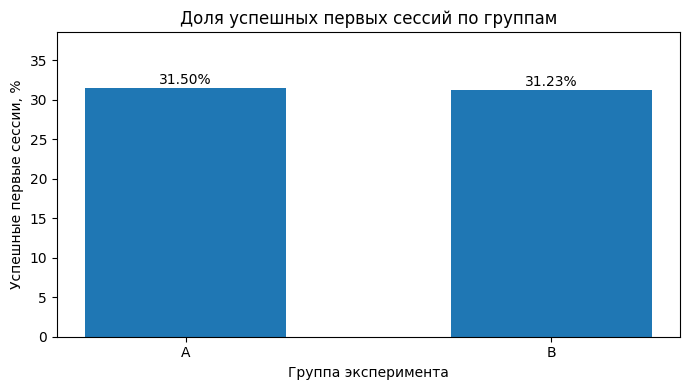

In [29]:
success_by_group = (first_ses.groupby('test_group')['good_session'].mean() * 100).reindex(['A', 'B'])
fig, ax = plt.subplots(figsize=(7, 4))
columns = ax.bar(success_by_group.index, success_by_group.values, width=0.55)
ax.set_ylabel('Успешные первые сессии, %')
ax.set_xlabel('Группа эксперимента')
ax.set_ylim(0, max(success_by_group) + 7)
ax.set_title('Доля успешных первых сессий по группам')
for bar, value in zip(columns, success_by_group.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.5, f'{value:.2f}%', ha='center')
plt.tight_layout()
plt.show()

## Итоги эксперимента

- Окно анализа: **14–20 октября 2025 года** (7 дней). **30 450** уникальных пользователей: 15 108 в группе A и 15 342 в группе B.
- Доля успешных первых сессий: **A — 31,50%**, **B — 31,23%**. Изменение B − A: **−0,265 процентного пункта** (относительно A: −0,84%).
- Односторонний z-тест долей: **p-value = 0,6911**. При α = 0,05 статистически значимого роста нет. **Рекомендация: не внедрять алгоритм массово** на основании этого эксперимента.
- A/B-проверка оценивает только основную метрику; вывод о влиянии на доходы и удержание нельзя делать без дополнительных данных и барьерных метрик.